# LSTM


W zadaniach NLP (Natural Language Processing), takich jak:
* analiza sentymentu,
* tłumaczenie maszynowe,
* generowanie tekstu,
* predykcja kolejnego słowa,
potrzebujemy modeli, które rozumieją sekwencję słów, a nie tylko pojedyncze słowa.

Tu właśnie używamy **LSTM** — sieci, która potrafi pamiętać kontekst w czasie (np. zależności gramatyczne lub semantyczne).


**Kiedy używać LSTM?**
- gdy sekwencje mają od umiarkowanej do dużej długości i **zależności czasowe są ważne**
- gdy mamy mało danych i nie chcemy używać cięższych modeli (np. transformery - to już niedługo :) ), albo chcemy modelu, który działa dobrze na mniejszych zbiorach
- do zadań sekwencyjnych

**Kiedy nie używać?**
- gdy mamy ogromne zbiory i potrzebujemy najlepszych wyników — transformery (np. BERT) często biją LSTM
- gdy zadanie wymaga globalnych zależności i kontekstów, które lepiej łapią mechanizmy self-attention


## Jak zbudowany jest LSTM?



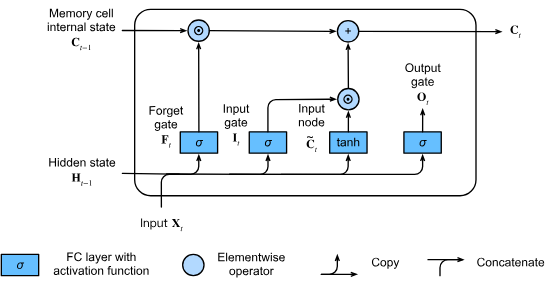


Podstawowy blok LSTM składa się z: stanu komórkowego (cell state) i wewnętrznych bramek:
 - **forget gate** (bramka zapominania) — decyduje, które informacje z poprzedniej komórki zignorować
 - **input gate** (bramka wejścia) — decyduje, które nowe informacje dodać
 - **output gate** (bramka wyjścia) — decyduje, jaka część stanu komórkowego stanie się wyjściem


## Przykład - przewidywanie kolejnego słowa w zdaniu


In [1]:
%pip install flair


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import random

from flair.data import Sentence
from flair.embeddings import FlairEmbeddings


In [3]:
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)


## Tworzymy słownik


In [4]:
sentences = [
  "It was a cold morning in October.",
  "Anna stood by the window, watching the fog rise over the city.",
  "She wrapped her scarf tighter and checked her phone.",
  "A message from Tom appeared: 'Are you ready for today?'.",
  "She smiled, remembering their plan.",
  "They were going to meet at the train station at dawn.",
  "The streets were silent, except for the sound of her footsteps.",
  "As she turned the corner, she saw a figure waiting in the mist.",
  "It was him."
]

# Inicjalizacja embeddingów
embedding = FlairEmbeddings('news-forward')

# dla każdego zdania tworzymy obiekty Sentence
flair_sentences = [Sentence(s) for s in sentences]

# Wydobycie embeddingów słów
for s in flair_sentences:
    embedding.embed(s)

# Zbudowanie słownika słów na podstawie korpusu
words = set(" ".join(sentences).split())
word2idx = {word: i+1 for i, word in enumerate(words)}  # indeksy od 1 (0 = padding)
idx2word = {i: word for word, i in word2idx.items()}
vocab_size = len(word2idx) + 1

print("Słownik:", word2idx)
print("Rozmiar słownika:", vocab_size)


/home/boro_arch_usr/Documents/Code/PJN/lab_03/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


Słownik: {'saw': 1, 'Anna': 2, 'watching': 3, 'window,': 4, 'of': 5, 'you': 6, 'turned': 7, 'corner,': 8, 'streets': 9, 'A': 10, 'tighter': 11, 'remembering': 12, 'sound': 13, 'mist.': 14, 'October.': 15, 'stood': 16, 'appeared:': 17, 'cold': 18, 'and': 19, 'were': 20, 'was': 21, 'her': 22, 'wrapped': 23, 'dawn.': 24, 'city.': 25, 'The': 26, 'in': 27, 'smiled,': 28, 'him.': 29, 'waiting': 30, 'As': 31, 'figure': 32, 'except': 33, 'ready': 34, 'silent,': 35, 'It': 36, 'their': 37, 'scarf': 38, 'message': 39, 'by': 40, 'the': 41, 'She': 42, 'They': 43, 'station': 44, 'from': 45, 'she': 46, 'at': 47, 'train': 48, 'meet': 49, 'going': 50, 'to': 51, 'Tom': 52, 'rise': 53, 'fog': 54, 'footsteps.': 55, "'Are": 56, 'checked': 57, 'plan.': 58, 'morning': 59, 'phone.': 60, 'over': 61, 'a': 62, 'for': 63, "today?'.": 64}
Rozmiar słownika: 65


Każde słowo dostaje unikalny numer.

Indeks 0 zarezerwowany na padding (wyrównywanie długości sekwencji).


## Przewidywanie kolejnego słowa


Będzi trenować lstm w kontekście całej sekwencji, żeby przewidywał nam kolejne słowo. Np: "To był chłodny" -> "poranek"


## Tworzymy dataset na podstawie nazszych zdań


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim


all_words = " ".join(sentences).split() # wszystkie słowa (to co mamy w słowniku)
seq_length = 4 # będziemy przewidywać piąte słowo na podstawie 4 poprzednich


X_data, y_data = [], []
# sztucznie tworzymy przykłady
for i in range(len(all_words) - seq_length):
  # przesuwamy nasze okienko sekwencji słów po tekście
  X_seq = all_words[i:i+seq_length]
  y_seq = all_words[i+seq_length]
  # nie używamy słów tylko index ze slownika
  X_data.append([word2idx[w] for w in X_seq])
  y_data.append(word2idx[y_seq])


# robimy tensory na których będziemy trenować
X = torch.tensor(X_data)
y = torch.tensor(y_data)


print(f"Sample input: {X_data[0]} -> target: {y_data[0]}")


Sample input: [36, 21, 62, 18] -> target: 59


Na co patrzymy?

Przygotowaliśmy sobie mechanizm że model dostaje 4 słowa (o indeksach 45, 20, 13, 17), a jego zadaniem jest przewidzieć kolejne słowo (o indeksie 5).


## Stwórzmy model


Stwórzmy model który od razu zrobi to co ręcznie zrobiliśmy u góry


In [6]:
class WordPredictorLSTM(nn.Module):
  def __init__(self, vocab_size, embedding_dim, hidden_dim):
    super().__init__()
    # to nasz embeding modelu - go też będziemy trenować!
    # każde słowo zamieniamy na wektor o długości embedding_dim
    self.embedding = nn.Embedding(vocab_size, embedding_dim)
    # tu jest nasz model :)
    self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
    # mapujemy wynik LSTM na rozkład prawdopodobieństwa z wszystkich słów w słowniku
    self.fc = nn.Linear(hidden_dim, vocab_size)


  def forward(self, x):
    # x - przyszło do nas słowo (index w słowniku)
    # zmieniamy index na wektor
    embeds = self.embedding(x)
    # przepuszczamy przez lstm
    # out: ukryte stany dla każdego kroku czasowego,
    # h: ostatni ukryty stan (zawiera podsumowanie sekwencji!) - Ważne !,
    # c: wewnętrzny stan pamięci.
    out, (h, c) = self.lstm(embeds)
    # ostatni ukryty stan, zwracamy prawdopodobieństwa - które słowo ma najwyzsze prawdopodobieństwo?
    return self.fc(h[-1])


model_word = WordPredictorLSTM(vocab_size=vocab_size, embedding_dim=100, hidden_dim=128)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_word.parameters(), lr=0.001)


## Trening


In [7]:
EPOCHS = 200
for epoch in range(EPOCHS):
  optimizer.zero_grad() # czyścimy gradienty
  output = model_word(X) # przewidywania modelu
  loss = criterion(output, y) # porównujemy przewidywanie vs rzeczywiste słowo
  loss.backward() # liczymy gradienty
  optimizer.step() # aktualizujemy wagi
  if (epoch+1) % 40 == 0:
    print(f"Epoch {epoch+1}/{EPOCHS}, Loss: {loss.item():.4f}")


Epoch 40/200, Loss: 1.5358


Epoch 80/200, Loss: 0.0876


Epoch 120/200, Loss: 0.0286


Epoch 160/200, Loss: 0.0163


Epoch 200/200, Loss: 0.0108


## Przetestujmy nasz model! 😺


In [8]:
def generate_text(model, seed_text, next_words=8):
  model.eval() # nie aktualizuj wag
  words = seed_text.split() # pierwsze zdanie zamieniamy na listę słów
  for _ in range(next_words): # generujemy tyle kolejnych słów ile chcemy
    seq = [word2idx.get(w, 0) for w in words[-seq_length:]] # zmieniamy na indeksy nasz kontekst, seq_length zdefiniowaliśmy podczas tworzenia datasetu
    x = torch.tensor(seq).unsqueeze(0) # tensor o wymiarze (1, długość kontekstu)
    with torch.no_grad():
      output = model(x) # przewidujemy na podstawie otrzymanych 4 słów
      predicted_idx = torch.argmax(output, dim=1).item() # wybieramy jakie słowo ma największe prawdopodobieństwo
      predicted_word = idx2word.get(predicted_idx, '') # indext wybranego słowa -> słowo
      words.append(predicted_word)
  return ' '.join(words) # zwracamy wszystko po kolei (nasza historia)


seed = "It was a cold"
print("Generated continuation:")
print(generate_text(model_word, seed))


Generated continuation:
It was a cold morning in October. Anna stood by the window,


## Zadanie


3 pkt

Stwórz sieć LSTM, która przewidzi kolejne zdanie a nie kolejne słowo


Input sentence → Encoder LSTM → Hidden state → Decoder LSTM → Predicted next sentence


UWAGA! Zproponowano szkielet LSTM SeqToSeq - ale jeśli chcesz zrobić to w inny sposób, użyć innych emebedingów itp - śmiało :)


In [9]:
sentences = [
    "It was a bright and sunny morning.",
    "The birds chirped happily in the trees.",
    "A cool breeze swept through the streets.",
    "Children played joyfully in the park.",
    "The cat lounged lazily on the windowsill.",
    "The coffee shop smelled of freshly brewed espresso.",
    "Raindrops pattered softly against the roof.",
    "The sky turned shades of pink and orange at sunset.",
    "A dog barked loudly at a passing car.",
    "The leaves rustled under the feet of walkers.",
    "Smoke rose from the chimney into the crisp air.",
    "The waves crashed rhythmically onto the shore.",
    "A lone cyclist rode along the quiet road.",
    "Flowers bloomed vibrantly in the garden.",
    "The old bookstore had a comforting aroma of paper.",
    "Fog rolled over the hills in the early morning.",
    "A gentle hum of traffic filled the city streets.",
    "The clock struck noon with a resounding chime.",
    "Windows rattled in the wind of the approaching storm.",
    "The bakery displayed an array of fresh pastries.",
    "A distant train whistle echoed through the valley.",
    "Stars twinkled faintly in the darkening sky.",
    "The playground was empty as dusk approached.",
    "A fisherman cast his line into the calm river.",
    "The scent of pine trees lingered in the air.",
    "Clouds gathered ominously over the mountains.",
    "The market buzzed with people and chatter.",
    "A child laughed as a balloon floated away.",
    "The lamp post flickered in the evening gloom.",
    "Shadows stretched long across the empty street.",
    "The fountain gurgled peacefully in the square.",
    "A paper airplane sailed across the classroom.",
    "The dog chased its tail in playful circles.",
    "The train station was crowded with travelers.",
    "Snowflakes drifted silently from the gray sky.",
    "A painter worked diligently on his canvas.",
    "The wind whispered secrets through the trees.",
    "A street musician played a soulful tune.",
    "The river sparkled under the midday sun.",
    "The fire crackled warmly in the hearth.",
    "A cyclist narrowly avoided a puddle on the road.",
    "The library was silent except for turning pages.",
    "The airplane soared high above the clouds.",
    "A butterfly landed delicately on a flower.",
    "The aroma of freshly baked bread filled the kitchen.",
    "The old clock ticked steadily in the hallway.",
    "A cat chased a shadow across the wall.",
    "The garden gate creaked in the evening breeze.",
    "The moon reflected off the still lake.",
    "A boy flew a kite on the open field.",
    "The streets glistened after a sudden rain shower."
]


In [12]:
import torch
import torch.nn as nn

from flair.data import Sentence
from flair.embeddings import FlairEmbeddings, DocumentPoolEmbeddings
# EMBEDINGI
token_embeddings = FlairEmbeddings("news-forward")

sentence_embeddings = DocumentPoolEmbeddings(
    [token_embeddings],
    pooling="mean",
    fine_tune_mode="none",
)

sentence_embeddings.eval()

flair_sentences = [Sentence(text) for text in sentences]

with torch.no_grad():
    for sentence in flair_sentences:
        sentence_embeddings.embed(sentence)

print("Pierwsze zdanie:", sentences[0])
print("Wymiar embeddingu pierwszego zdania:", flair_sentences[0].embedding.shape)


context_length = 3

X_seq = torch.stack([
    sentence_vectors[i:i + context_length]
    for i in range(len(sentence_vectors) - context_length)
])

y_seq = sentence_vectors[context_length:].unsqueeze(1)

# jeśli tu jest zero to prawdopodobnie coś poszło nie tak :)
print("X_seq wymiar:", X_seq.shape)
print("Y_seq wymiar:", y_seq.shape)

# MODEL
class Seq2SeqLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()

        self.encoder = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True,
        )

        self.decoder = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True,
        )

        self.fc = nn.Linear(hidden_dim, input_dim)

    def forward(self, x):
        _, (h, c) = self.encoder(x)

        decoder_input = x.new_zeros(x.size(0), 1, x.size(2))

        decoder_output, _ = self.decoder(decoder_input, (h, c))

        return self.fc(decoder_output)

input_dim = X_seq.shape[2]
hidden_dim = 64
model_seq = Seq2SeqLSTM(input_dim, hidden_dim)

with torch.no_grad():
    prediction = model_seq(X_seq)

print("Przewidywanie:", prediction.shape)
print("Oczekiwany wynik:", y_seq.shape)

assert prediction.shape == y_seq.shape

criterion_seq = nn.MSELoss()
optimizer_seq = optim.Adam(model_seq.parameters(), lr=0.003)


EPOCHS = 400

model_seq.train()

for epoch in range(EPOCHS):
    optimizer_seq.zero_grad()

    prediction = model_seq(X_seq)
    loss = criterion_seq(prediction, y_seq)

    loss.backward()
    optimizer_seq.step()

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoka {epoch + 1}/{EPOCHS}, "
            f"MSE: {loss.item():.6f}"
        )


Pierwsze zdanie: It was a bright and sunny morning.
Wymiar embeddingu pierwszego zdania: torch.Size([2048])
X_seq wymiar: torch.Size([48, 3, 2048])
Y_seq wymiar: torch.Size([48, 1, 2048])
Przewidywanie: torch.Size([48, 1, 2048])
Oczekiwany wynik: torch.Size([48, 1, 2048])


Epoka 100/400, MSE: 0.000387


Epoka 200/400, MSE: 0.000222


Epoka 300/400, MSE: 0.000121


Epoka 400/400, MSE: 0.000072


UWAGA: **Twój model nie jest modelem generatywnym**! Twój LSTM przewiduje embedding następnego zdania, a my znajdziemy w zbiorze zdań to, które jest najbardziej podobne.


In [18]:
import torch
import torch.nn.functional as F

device = next(model_seq.parameters()).device
vectors = sentence_vectors.to(device)

# Podajemy 3 zdania startowe (ostatnie zdanie z naszej sekwencji)
X_input = vectors[-context_length:].unsqueeze(0)

# Model w trybie ewaluacyjnym
model_seq.eval()
with torch.no_grad():
    predicted_embedding = model_seq(X_input)

print("Wejście inferencji:", X_input.shape)
print("Wyjście inferencji:", predicted_embedding.shape)

# Zamieniamy na 1D tensor
pred_emb = predicted_embedding.squeeze(0).squeeze(0)
# dużo problemów w AI to niezgadzające się shape'y - PAMIĘTAJ PRINTOWAĆ ROZMIAR jesli coś nie gra

# Tworzymy listę embeddingów wszystkich zdań w zbiorze
emb_list = [s.embedding.to(pred_emb.device) for s in flair_sentences]
# Obliczamy podobieństwo cosinusowe do wszystkich zdań
similarities = [F.cosine_similarity(pred_emb, e, dim=0) for e in emb_list]
# Wybieramy indeks najbardziej podobnego zdania
best_idx = torch.argmax(torch.tensor(similarities))
# wygląda jak niedawne zadanie z labów z wektorami słów, prawda? :)

print('Początek historii: ', flair_sentences[-context_length:])
print("Przewidziane kolejne zdanie (najbliżej w naszym zestawie):")
print(sentences[best_idx])


Wymiary przewidzianego embedingu torch.Size([1, 1, 2048])
Początek historii:  [Sentence[8]: "The moon reflected off the still lake.", Sentence[10]: "A boy flew a kite on the open field.", Sentence[9]: "The streets glistened after a sudden rain shower."]
Przewidziane kolejne zdanie (najbliżej w naszym zestawie):
A lone cyclist rode along the quiet road.
